📊 Projeto Final: Modelo de Classificação para Risco de Crédito

**Autores:** Eduardo Roquette / Fernando Araújo / Gustavo Bogéa
**Data:** Novembro/2026

ETAPA 1: DESCRIÇÃO DO PROBLEMA

**Objetivo:** Desenvolver um algoritmo de Machine Learning capaz de classificar clientes conforme a ocorrência de atrasos em seu histórico de crédito, considerando registros de pagamento classificados nos status de `1` a `5`. O projeto utiliza informações cadastrais, financeiras e demográficas, como renda anual e idade, para identificar padrões associados ao comportamento histórico de pagamento e comparar diferentes modelos de classificação quanto à capacidade de distinguir clientes com e sem registros de atraso.

**Decisão que o Modelo apoia:** O modelo busca fornecer informações que possam contribuir para a análise de risco de crédito, identificando perfis associados à ocorrência histórica de atrasos. Sua utilização em decisões reais de concessão de crédito dependeria de validação temporal, análise de custos e avaliação com novos dados.

**Relevância do Tema:** No setor financeiro, a concessão de crédito sem uma análise de risco adequada acarreta altas taxas de inadimplência (prejuízo financeiro direto) ou a recusa desnecessária de clientes solventes (perda de receita e oportunidades de mercado).


ETAPA 2: PRÉ-PROCESSAMENTO E ANÁLISE EXPLORATÓRIA

Nesta etapa, preparamos a base de dados para a modelagem preditiva, garantindo a integridade e a qualidade das informações provenientes do histórico financeiro e cadastral dos clientes.

### Principais Ações Realizadas:
* **União das Bases (`Merge`):** Junção dos dados cadastrais (`application_record.csv`) com o histórico de pagamentos mensal (`credit_record.csv`) utilizando a chave unificadora de identificação do cliente (`id_cliente`).
* **Criação da Variável Alvo (`Target`):** A variável alvo foi construída a partir dos registros mensais do histórico de crédito. Clientes que apresentaram pelo menos um status de pagamento entre `1` e `5`, abrangendo atrasos de 1 a 29 dias até faixas superiores de atraso, foram classificados na classe positiva (`1`). Os demais receberam a classificação `0`, indicando ausência desses registros de atraso no período observado. A agregação foi realizada por cliente, utilizando o valor máximo da variável binária ao longo dos meses disponíveis. Dessa forma, o modelo busca identificar perfis associados à ocorrência histórica de atrasos, sem estabelecer uma previsão temporal de inadimplência futura.
* **Engenharia de Recursos (*Feature Engineering*):** 
  * Conversão de variáveis temporais (como dias trabalhados e idade) para unidades mais intuitivas (anos).
  * Tratamento e codificação de variáveis categóricas (como tipo de renda, escolaridade, estado civil e tipo de moradia).
  * Imputação de valores ausentes em colunas categóricas e numéricas quando aplicável.
* **Divisão dos Dados:** Separação do conjunto de dados em treino, validação e teste utilizando amostragem estratificada (`stratify=y`) para preservar a proporção de desbalanceamento da classe alvo em ambos os conjuntos.
* **Normalização:** Aplicação de escala padrão (`StandardScaler`) estritamente nos dados voltados para o modelo de Regressão Logística, preservando a estrutura original para o XGBoost.
* **Verificação de duplicações:** Foi realizada uma análise de duplicações utilizando o identificador único dos clientes (`id_cliente`). A base cadastral apresentou 47 ocorrências de identificadores repetidos. Entretanto, após as etapas de preparação e integração dos dados, a base final utilizada na modelagem apresentou 36.457 registros, correspondentes a 36.457 clientes únicos, sem duplicações de identificadores. Dessa forma, não foi identificada sobreposição de clientes entre os conjuntos de treinamento, validação e teste decorrente de registros duplicados.

In [1]:
# 1. IMPORT DAS BIBLIOTECAS E CONFIGURAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, 
                             roc_auc_score, roc_curve, accuracy_score, 
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier, plot_importance
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 130)

In [2]:
# 2. LEITURA DOS DADOS
ARQUIVO_CADASTRO = 'dados/application_record.csv'
ARQUIVO_CREDITO = 'dados/credit_record.csv'

df_clientes = pd.read_csv(ARQUIVO_CADASTRO)
df_credito = pd.read_csv(ARQUIVO_CREDITO)

print("SHAPE | df_clientes:", df_clientes.shape)
print("SHAPE | df_credito:", df_credito.shape)

SHAPE | df_clientes: (438557, 18)
SHAPE | df_credito: (1048575, 3)


In [3]:
# 3. TRATAMENTO INICIAL E RENOMEAÇÃO DE COLUNAS
novos_nomes_clientes = {
    'ID': 'id_cliente', 'CODE_GENDER': 'genero', 'FLAG_OWN_CAR': 'possui_carro',
    'FLAG_OWN_REALTY': 'possui_imovel', 'CNT_CHILDREN': 'qtd_filhos', 
    'AMT_INCOME_TOTAL': 'renda_anual', 'NAME_INCOME_TYPE': 'tipo_renda',
    'NAME_EDUCATION_TYPE': 'escolaridade', 'NAME_FAMILY_STATUS': 'estado_civil',
    'NAME_HOUSING_TYPE': 'tipo_moradia', 'DAYS_BIRTH': 'dias_nascimento',
    'DAYS_EMPLOYED': 'dias_empregado', 'FLAG_MOBIL': 'possui_celular',
    'FLAG_WORK_PHONE': 'possui_tel_trabalho', 'FLAG_PHONE': 'possui_tel_fixo',
    'FLAG_EMAIL': 'possui_email', 'OCCUPATION_TYPE': 'ocupacao',
    'CNT_FAM_MEMBERS': 'qtd_membros_familia'
}

df_clientes = df_clientes.rename(columns=novos_nomes_clientes)
df_credito = df_credito.rename(columns={'ID': 'id_cliente', 'MONTHS_BALANCE': 'mes_referencia', 'STATUS': 'status_pagamento'})

In [4]:
# 4. ENGENHARIA DE FEATURES (Criação de novas variáveis numéricas)
df_clientes["idade"] = (-df_clientes["dias_nascimento"] / 365.25).astype(int)
df_clientes["anos_emprego"] = (-df_clientes["dias_empregado"] / 365.25).clip(lower=0).round(1)

# OBS: Optou-se por NÃO remover outliers (ex: limite de IQR em renda_anual) 
# para preservar a variabilidade do mundo real e testar a robustez dos modelos.

In [5]:
# 5. PADRONIZAÇÃO DAS VARIÁVEIS CATEGÓRICAS (Mapeamentos e Imputação)
mapa_ocupacao = {'Security staff': 'Equipe de Segurança', 'Sales staff': 'Vendas', 'Accountants': 'Contadores', 'Laborers': 'Operários', 'Managers': 'Gerentes', 'Drivers': 'Motoristas', 'Core staff': 'Equipe Principal', 'High skill tech staff': 'Equipe Técnica Especializada', 'Cleaning staff': 'Equipe de Limpeza', 'Private service staff': 'Serviços Privados', 'Cooking staff': 'Cozinha', 'Low-skill Laborers': 'Trabalhadores Operacionais', 'Medicine staff': 'Equipe de Saúde', 'Secretaries': 'Secretários(as)', 'Waiters/barmen staff': 'Garçons/Bartenders', 'HR staff': 'Recursos Humanos', 'Realty agents': 'Corretores de Imóveis', 'IT staff': 'Equipe de TI'}
mapa_tipo_renda = {'Working': 'Empregado', 'Commercial associate': 'Autônomo / Comercial', 'Pensioner': 'Aposentado / Pensionista', 'State servant': 'Servidor Público', 'Student': 'Estudante'}
mapa_estado_civil = {'Married': 'Casado(a)', 'Single / not married': 'Solteiro(a)', 'Civil marriage': 'União Estável', 'Separated': 'Separado(a)', 'Widow': 'Viúvo(a)'}
mapa_tipo_moradia = {'House / apartment': 'Casa / Apartamento Próprio', 'With parents': 'Com os Pais', 'Municipal apartment': 'Habitação Pública', 'Rented apartment': 'Aluguel', 'Office apartment': 'Alojamento da Empresa', 'Co-op apartment': 'Cooperativa Habitacional'}
mapa_escolaridade_pt = {'Secondary / secondary special': 'Ensino Médio / Técnico', 'Higher education': 'Ensino Superior', 'Incomplete higher': 'Superior Incompleto', 'Lower secondary': 'Ensino Fundamental', 'Academic degree': 'Pós-Graduação'}
mapeamento_escolaridade_num = {'Ensino Fundamental': 1, 'Ensino Médio / Técnico': 2, 'Superior Incompleto': 3, 'Ensino Superior': 4, 'Pós-Graduação': 5}

df_clientes['ocupacao'] = df_clientes['ocupacao'].replace(mapa_ocupacao)
df_clientes['tipo_renda'] = df_clientes['tipo_renda'].replace(mapa_tipo_renda)
df_clientes['estado_civil'] = df_clientes['estado_civil'].replace(mapa_estado_civil)
df_clientes['tipo_moradia'] = df_clientes['tipo_moradia'].replace(mapa_tipo_moradia)

# Aplicando a tradução e depois transformando em número ordinal
df_clientes['escolaridade'] = df_clientes['escolaridade'].replace(mapa_escolaridade_pt)
df_clientes['escolaridade'] = df_clientes['escolaridade'].map(mapeamento_escolaridade_num)

In [6]:
# Transformação das Variáveis Binárias
colunas_binarias = ['possui_carro', 'possui_imovel']
for col in colunas_binarias:
    df_clientes[col] = df_clientes[col].map({'N': 0, 'Y': 1})

In [7]:
# Imputação de Nulos em Ocupação
condicoes = [(df_clientes["ocupacao"].isna()) & (df_clientes["tipo_renda"] == "Aposentado / Pensionista"), (df_clientes["ocupacao"].isna())]
df_clientes["ocupacao"] = np.select(condicoes, ["Pensionista", "Nao especificado"], default=df_clientes["ocupacao"])

In [8]:
# 6. CRIAÇÃO DA VARIÁVEL ALVO (TARGET)

# Status 1 a 5: ocorrência de atraso no pagamento,
# incluindo atrasos de 1 a 29 dias e faixas superiores.
status_atraso = ['1', '2', '3', '4', '5']

df_credito['inadimplente'] = (
    df_credito['status_pagamento']
    .isin(status_atraso)
    .astype(int)
)

# Agregação por cliente:
# 1 = apresentou pelo menos um atraso no histórico
# 0 = não apresentou atrasos dos status 1 a 5
df_target = (
    df_credito.groupby('id_cliente')['inadimplente']
    .max()
    .reset_index()
)

# Cruzamento das bases
df_final = pd.merge(
    df_clientes,
    df_target,
    on='id_cliente',
    how='inner'
)

print("SHAPE | DF_FINAL:", df_final.shape)


SHAPE | DF_FINAL: (36457, 21)


In [9]:
# AUDITORIA: VERIFICAÇÃO DE CLIENTES DUPLICADOS

# Duplicações na base cadastral
duplicados_cadastro = df_clientes["id_cliente"].duplicated().sum()

# Duplicações na base final
duplicados_final = df_final["id_cliente"].duplicated().sum()

# Quantidade de clientes únicos
clientes_unicos = df_final["id_cliente"].nunique()

print("Registros duplicados no cadastro:", duplicados_cadastro)
print("Registros duplicados na base final:", duplicados_final)
print("Total de clientes únicos na base final:", clientes_unicos)
print("Total de linhas da base final:", len(df_final))

# 4. Exibir exemplos, caso existam
if duplicados_final > 0:
    display(
        df_final[
            df_final["id_cliente"].duplicated(keep=False)
        ].sort_values("id_cliente").head(10)
    )


Registros duplicados no cadastro: 47
Registros duplicados na base final: 0
Total de clientes únicos na base final: 36457
Total de linhas da base final: 36457


In [10]:
# 7. PREPARAÇÃO PARA MODELAGEM (Encoding e Split)
features_selecionadas = [
    'renda_anual', 'idade', 'anos_emprego', 'qtd_membros_familia',
    'possui_imovel', 'possui_carro', 'tipo_renda', 'escolaridade', 
    'estado_civil', 'tipo_moradia', 'ocupacao'
]

X = df_final[features_selecionadas]
y = df_final['inadimplente']

In [11]:
# Separação Treino / Validação / Teste
# Realizada antes do pré-processamento

X_dev, X_test_raw, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Treino:", len(X_train_raw))
print("Validação:", len(X_val_raw))
print("Teste:", len(X_test_raw))


Treino: 21873
Validação: 7292
Teste: 7292


In [12]:
# Pré-processamento ajustado apenas no treino

colunas_categoricas = [
    'tipo_renda', 'estado_civil',
    'tipo_moradia', 'ocupacao'
]

colunas_numericas = [
    col for col in X.columns
    if col not in colunas_categoricas
]

pipeline_numerico = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

pipeline_categorico = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first',
        sparse_output=False
    ))
])

preprocessador = ColumnTransformer([
    ('num', pipeline_numerico, colunas_numericas),
    ('cat', pipeline_categorico, colunas_categoricas)
], verbose_feature_names_out=False)

# Aprendizado somente com os dados de treino
X_train_array = preprocessador.fit_transform(X_train_raw)

# Aplicação das mesmas transformações
X_val_array = preprocessador.transform(X_val_raw)
X_test_array = preprocessador.transform(X_test_raw)

# Nomes das variáveis resultantes
nomes_features = preprocessador.get_feature_names_out()

X_train = pd.DataFrame(
    X_train_array,
    columns=nomes_features,
    index=X_train_raw.index
)

X_val = pd.DataFrame(
    X_val_array,
    columns=nomes_features,
    index=X_val_raw.index
)

X_test = pd.DataFrame(
    X_test_array,
    columns=nomes_features,
    index=X_test_raw.index
)

print("Total de features:", X_train.shape[1])


Total de features: 39


In [13]:
# Escalonamento apenas para Regressão Logística
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

ETAPA 3: DEFINIÇÃO DA TAREFA

* **Tipo de Tarefa:** Aprendizado **Supervisionado**.
* **Subcategoria:** **Classificação Binária**.
* **Justificativa:** O problema consiste em classificar clientes em duas categorias: `0`, quando não há registros de atraso classificados nos status de `1` a `5` no histórico observado, e `1`, quando existe pelo menos uma ocorrência dessas categorias. Como a variável alvo foi construída a partir de registros históricos de pagamento, o problema caracteriza-se como uma tarefa de classificação binária supervisionada. O modelo busca aprender associações entre características cadastrais e financeiras e a ocorrência histórica de atrasos, não sendo possível afirmar, com a metodologia atual, que prevê inadimplência futura.

In [14]:
# 8. FUNÇÃO DE AVALIAÇÃO DE PERFORMANCE
resultados = []

def avaliar(nome, y_real, y_previsto, y_prob=None):
    resultados.append({
        'modelo': nome,
        'acurácia': accuracy_score(y_real, y_previsto),
        'precisão': precision_score(y_real, y_previsto, zero_division=0),
        'recall': recall_score(y_real, y_previsto),
        'F1': f1_score(y_real, y_previsto),
        'ROC-AUC': roc_auc_score(y_real, y_prob) if y_prob is not None else np.nan,
    })
    return pd.DataFrame(resultados).round(3)

ETAPA 4: CONSTRUÇÃO DO MODELO

**Modelo de Referência (Baseline):** Estabelecemos uma referência simples inicial (como prever sempre a classe majoritária ou utilizar um `DummyClassifier`) para servir de parâmetro mínimo de comparação de desempenho.
  
* **Algoritmos Utilizados:** Implementação de modelos adequados ao problema de classificação de risco de crédito:
  * **Regressão Logística:** Modelo linear robusto e altamente interpretável (utilizado com dados padronizados e pesos balanceados).
  * **XGBoost:** Algoritmo de *Gradient Boosting* baseado em árvores, capaz de capturar relações complexas e não-lineares nos dados.

In [15]:
# 9. MODELO DE REFERÊNCIA (BASELINE)

from sklearn.dummy import DummyClassifier

# Modelo que sempre prevê a classe majoritária
baseline = DummyClassifier(strategy='most_frequent')

# Treinamento
baseline.fit(X_train, y_train)

# Previsões
y_pred_baseline = baseline.predict(X_test)
y_prob_baseline = baseline.predict_proba(X_test)[:, 1]

# Avaliação
avaliar(
    'Baseline (DummyClassifier)',
    y_test,
    y_pred_baseline,
    y_prob_baseline
)


,modelo,acurácia,precisão,recall,F1,ROC-AUC
0,Baseline (DummyClassifier),0.882,0.0,0.0,0.0,0.5


In [16]:
# 10. MODELO 1: REGRESSÃO LOGÍSTICA
modelo_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_scaled, y_train)

y_pred = modelo_lr.predict(X_test_scaled)
y_prob = modelo_lr.predict_proba(X_test_scaled)[:, 1]

In [17]:
# Cálculo do limiar ótimo na VALIDAÇÃO
y_prob_val = modelo_lr.predict_proba(X_val_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_val, y_prob_val)

j_youden = tpr - fpr
limiar_otimo = thresholds[np.argmax(j_youden)]

print(f"Limiar ótimo LR: {limiar_otimo:.4f}")

Limiar ótimo LR: 0.5100


In [18]:
# Limiar de Negócio
limiar_negocio = 0.35
y_pred_otimo = (y_prob >= limiar_otimo).astype(int)
y_pred_negocio = (y_prob >= limiar_negocio).astype(int)

In [19]:
# Registrando resultados
df_resultados = avaliar('Regressão Logística (Padrão 0.50)', y_test, y_pred, y_prob)
df_resultados = avaliar(f'Regressão Logística (Ótimo {limiar_otimo:.2f})', y_test, y_pred_otimo, y_prob)
df_resultados = avaliar(f'Regressão Logística (Negócio {limiar_negocio:.2f})', y_test, y_pred_negocio, y_prob)

In [20]:
print("Quantidade de features:", X_train.shape[1])
print("Quantidade de coeficientes:", len(modelo_lr.coef_[0]))

Quantidade de features: 39
Quantidade de coeficientes: 39


In [21]:
# Coeficientes da Regressão Logística

coeficientes = pd.DataFrame({
    'Feature': X_train.columns,
    'Coeficiente': modelo_lr.coef_[0]
}).sort_values(
    by='Coeficiente',
    ascending=False
)

print("--- Top 5 Fatores que Aumentam o Risco ---")
print(coeficientes.head(5))

print("\n--- Top 5 Fatores que Diminuem o Risco ---")
print(coeficientes.tail(5))


--- Top 5 Fatores que Aumentam o Risco ---
                                Feature  Coeficiente
37  ocupacao_Trabalhadores Operacionais     0.048673
3                   qtd_membros_familia     0.047901
26         ocupacao_Equipe de Segurança     0.043038
0                           renda_anual     0.041408
12             estado_civil_Solteiro(a)     0.028667

--- Top 5 Fatores que Diminuem o Risco ---
                            Feature  Coeficiente
4                     possui_imovel    -0.087502
10      tipo_renda_Servidor Público    -0.736945
33             ocupacao_Pensionista    -1.062457
7   tipo_renda_Autônomo / Comercial    -1.151397
8              tipo_renda_Empregado    -1.409540


In [22]:
# 11. MODELO 2: XGBOOST
peso_classes = y_train.value_counts()[0] / y_train.value_counts()[1]

modelo_xgb = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=5,
    scale_pos_weight=peso_classes, random_state=42, eval_metric='logloss'
)
# XGBoost não precisa de dados escalonados, usamos X_train original encodado
modelo_xgb.fit(X_train, y_train) 

y_pred_xgb = modelo_xgb.predict(X_test)
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

In [23]:
# Cálculo do limiar ótimo XGBoost na VALIDAÇÃO
y_prob_val_xgb = modelo_xgb.predict_proba(X_val)[:, 1]

fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(
    y_val, y_prob_val_xgb
)

j_youden_xgb = tpr_xgb - fpr_xgb
limiar_otimo_xgb = thresholds_xgb[np.argmax(j_youden_xgb)]

print(f"Limiar ótimo XGBoost: {limiar_otimo_xgb:.4f}")


Limiar ótimo XGBoost: 0.4776


In [24]:
# Limiares de Negócio XGBoost
limiar_negocio_xgb = 0.30
limiar_comercial_xgb = 0.45

# Previsões para cada limiar
y_pred_otimo_xgb = (y_prob_xgb >= limiar_otimo_xgb).astype(int)
y_pred_negocio_xgb = (y_prob_xgb >= limiar_negocio_xgb).astype(int)
y_pred_comercial_xgb = (y_prob_xgb >= limiar_comercial_xgb).astype(int)


In [25]:

# Registrando resultados XGBoost
df_resultados = avaliar('XGBoost (Padrão 0.50)', y_test, y_pred_xgb, y_prob_xgb)
df_resultados = avaliar(f'XGBoost (Ótimo {limiar_otimo_xgb:.2f})', y_test, y_pred_otimo_xgb, y_prob_xgb)
df_resultados = avaliar(f'XGBoost (Comercial {limiar_comercial_xgb:.2f})', y_test, y_pred_comercial_xgb, y_prob_xgb)
df_resultados = avaliar(f'XGBoost (Negócio {limiar_negocio_xgb:.2f})', y_test, y_pred_negocio_xgb, y_prob_xgb)


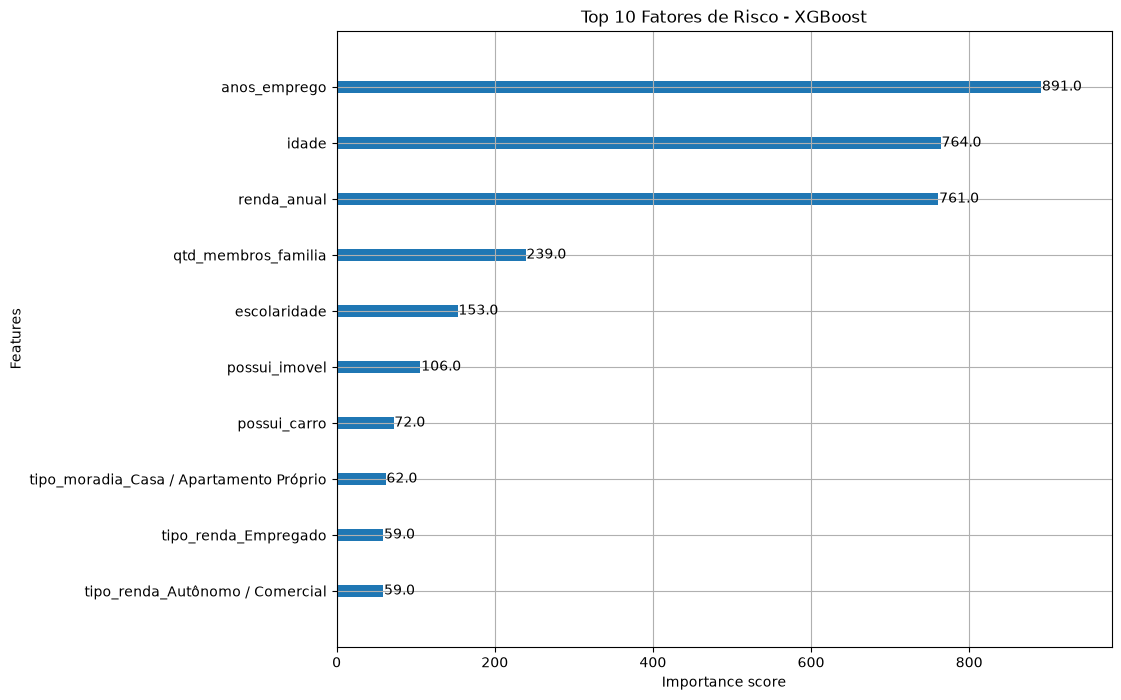

In [26]:
# Visualizando Feature Importance do XGBoost
fig, ax = plt.subplots(figsize=(10, 8))
plot_importance(modelo_xgb, ax=ax, max_num_features=10, title="Top 10 Fatores de Risco - XGBoost")
plt.show()

In [27]:
# Tabela Comparativa Final

df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.drop_duplicates(
    subset=['modelo'],
    keep='last'
).reset_index(drop=True)
display(df_resultados)


,modelo,acurácia,precisão,recall,F1,ROC-AUC
0,Baseline (DummyClassifier),0.882337,0.000000,0.000000,0.000000,0.500000
1,Regressão Logística (Padrão 0.50),0.554580,0.132534,0.502331,0.209732,0.544797
2,Regressão Logística (Ótimo 0.51),0.616292,0.136976,0.426573,0.207365,0.544797
3,Regressão Logística (Negócio 0.35),0.126714,0.118315,0.995338,0.211491,0.544797
4,XGBoost (Padrão 0.50),0.698300,0.199103,0.517483,0.287565,0.670588
5,XGBoost (Ótimo 0.48),0.640154,0.181687,0.587413,0.277533,0.670588
6,XGBoost (Comercial 0.45),0.571997,0.171362,0.687646,0.274355,0.670588
7,XGBoost (Negócio 0.30),0.239166,0.126592,0.926573,0.222751,0.670588


ETAPA 5: AVALIAÇÃO

* **Métricas Apropriadas ao Problema:** Para avaliar os modelos de classificação de risco de crédito, evitamos utilizar exclusivamente a acurácia, que pode ser enganosa devido ao desbalanceamento das classes. Foram utilizadas métricas como ROC-AUC, Recall, Precisão e F1-Score.

  * **ROC-AUC:** Mede a capacidade do modelo de discriminar clientes com e sem registros históricos de atraso.

  * **Recall (Sensibilidade):** Indica a proporção de clientes com histórico de atrasos que o modelo consegue identificar corretamente.

  * **Precisão:** Indica a proporção de clientes classificados como pertencentes à classe positiva que realmente apresentaram registros históricos de atraso.

  * **F1-Score:** Representa a média harmônica entre precisão e recall, permitindo avaliar o equilíbrio entre essas duas métricas.

* **Leitura na Unidade de Negócio:** A variável alvo foi definida pela ocorrência de pelo menos um registro de atraso nos status `1` a `5`, incluindo atrasos inferiores a 30 dias.

  * **Falsos positivos:** Clientes sem registros dessas categorias de atraso no histórico observado que foram classificados incorretamente como pertencentes à classe positiva.

  * **Falsos negativos:** Clientes com pelo menos um registro histórico de atraso nos status `1` a `5` que não foram identificados pelo modelo.

  Em uma aplicação real, esses erros poderiam gerar impactos financeiros distintos. Entretanto, sua quantificação dependeria de informações adicionais sobre concessão de crédito, perdas financeiras e rentabilidade. Como o projeto utiliza uma classificação baseada no histórico observado, os resultados não devem ser interpretados como previsões comprovadas de inadimplência futura.

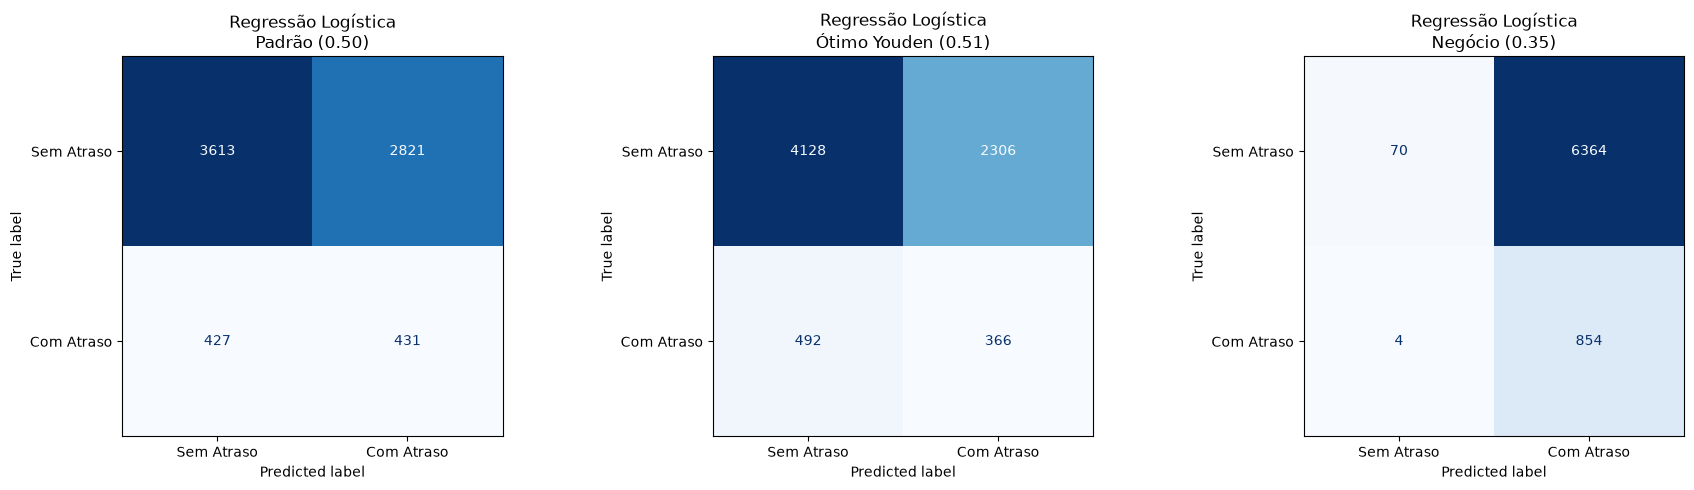

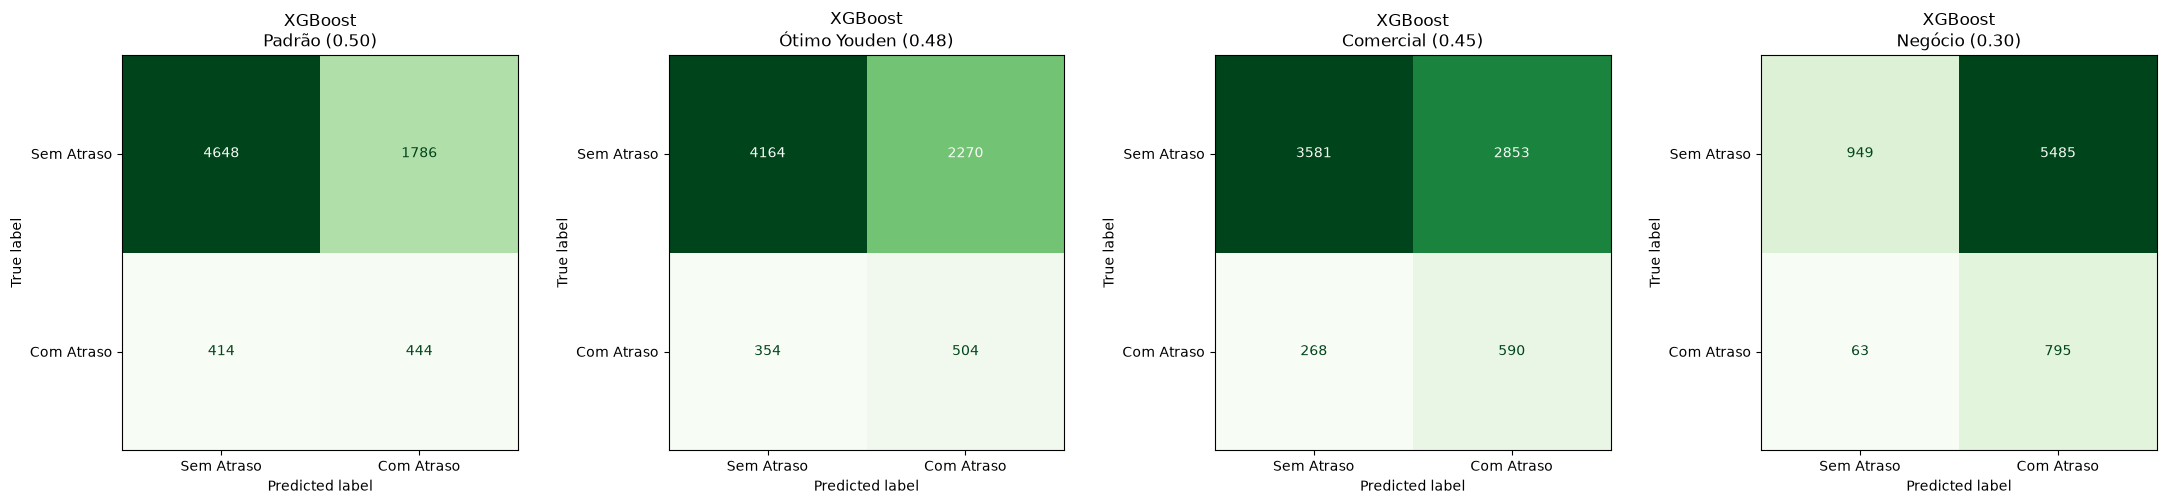


=== COMPARATIVO FINAL DE PERFORMANCE ===


,modelo,acurácia,precisão,recall,F1,ROC-AUC
0,Baseline (DummyClassifier),0.882337,0.000000,0.000000,0.000000,0.500000
1,Regressão Logística (Padrão 0.50),0.554580,0.132534,0.502331,0.209732,0.544797
2,Regressão Logística (Ótimo 0.51),0.616292,0.136976,0.426573,0.207365,0.544797
3,Regressão Logística (Negócio 0.35),0.126714,0.118315,0.995338,0.211491,0.544797
4,XGBoost (Padrão 0.50),0.698300,0.199103,0.517483,0.287565,0.670588
5,XGBoost (Ótimo 0.48),0.640154,0.181687,0.587413,0.277533,0.670588
6,XGBoost (Comercial 0.45),0.571997,0.171362,0.687646,0.274355,0.670588
7,XGBoost (Negócio 0.30),0.239166,0.126592,0.926573,0.222751,0.670588


In [28]:
# 12. MATRIZES DE CONFUSÃO COMPARATIVAS

# Regressão Logística: 3 cenários
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cenarios_lr = [
    ('Padrão (0.50)', y_pred),
    (f'Ótimo Youden ({limiar_otimo:.2f})', y_pred_otimo),
    (f'Negócio ({limiar_negocio:.2f})', y_pred_negocio)
]

for ax, (titulo, predicao) in zip(axes, cenarios_lr):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicao,
        display_labels=['Sem Atraso', 'Com Atraso'],
        cmap='Blues',
        values_format='d',
        ax=ax,
        colorbar=False
    )
    ax.set_title(f'Regressão Logística\n{titulo}')

plt.tight_layout()
plt.show()


# XGBoost: 4 cenários
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

cenarios_xgb = [
    ('Padrão (0.50)', y_pred_xgb),
    (f'Ótimo Youden ({limiar_otimo_xgb:.2f})',
     y_pred_otimo_xgb),
    (f'Comercial ({limiar_comercial_xgb:.2f})',
     y_pred_comercial_xgb),
    (f'Negócio ({limiar_negocio_xgb:.2f})',
     y_pred_negocio_xgb)
]

for ax, (titulo, predicao) in zip(axes, cenarios_xgb):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicao,
        display_labels=['Sem Atraso', 'Com Atraso'],
        cmap='Greens',
        values_format='d',
        ax=ax,
        colorbar=False
    )
    ax.set_title(f'XGBoost\n{titulo}')

plt.tight_layout()
plt.show()


# 13. TABELA FINAL DE RESULTADOS
print("\n=== COMPARATIVO FINAL DE PERFORMANCE ===")
display(df_resultados)


ETAPA 6: BOAS PRÁTICAS, CONFORME NECESSIDADE

Para assegurar a robustez, confiabilidade e aplicabilidade real da solução de machine learning, foram adotadas as seguintes boas práticas ao longo do projeto:

* **Prevenção de Overfitting:** Utilização de regularização nos modelos lineares e limitação na complexidade/profundidade das árvores do XGBoost, além de validação rigorosa para garantir que o modelo generalize bem para novos dados de clientes.
* **Tratamento de Classes Desbalanceadas:** Aplicação de ponderação de classes (`class_weight='balanced'` na Regressão Logística e `scale_pos_weight` no XGBoost) para compensar a menor frequência de clientes com registros históricos de atraso, reduzindo a tendência dos modelos de favorecer exclusivamente a classe majoritária.
* **Prevenção de Vazamento de Informações (Data Leakage):** A divisão dos dados em treinamento (60%), validação (20%) e teste (20%) foi realizada antes do ajuste das transformações de pré-processamento. A imputação de valores ausentes e a codificação das variáveis categóricas foram implementadas com `Pipeline` e `ColumnTransformer`, utilizando exclusivamente o conjunto de treinamento para aprender os parâmetros necessários. O `StandardScaler` também foi ajustado somente no treinamento e aplicado posteriormente aos conjuntos de validação e teste. Além disso, os limiares de classificação foram selecionados utilizando a validação, preservando o teste para a avaliação final dos modelos.

## Avaliação de Métricas e Decisão de Negócio

### 1. Comparação com o Modelo de Referência (Baseline)

O modelo de referência (`DummyClassifier`) apresentou **88,2% de acurácia**, porém com **Recall de 0% e ROC-AUC de 0,500**. Isso ocorre porque ele classifica todos os clientes como pertencentes à classe negativa, ou seja, sem registros históricos de atraso dos status `1` a `5`, deixando de identificar todos os clientes da classe positiva.

Esse resultado demonstra que a acurácia isoladamente não é suficiente para avaliar modelos de risco de crédito, especialmente em bases desbalanceadas.

### 2. Desempenho da Regressão Logística

A Regressão Logística apresentou **ROC-AUC de 0,545**, indicando baixa capacidade de discriminação entre clientes com e sem registros históricos de atraso.

No limiar padrão de 0,50, o modelo alcançou **Recall de 50,2% e acurácia de 55,5%**.

O limiar de Youden, calculado no conjunto de validação, foi de **0,51**. Aplicado ao conjunto de teste, resultou em **Recall de 42,7% e acurácia de 61,6%**.

No cenário de negócio com limiar de 0,35, o Recall aumentou para **99,5%**, mas a acurácia caiu para **12,7%**, indicando uma quantidade muito elevada de falsos positivos.

Esses resultados mostram que a Regressão Logística apresenta limitações importantes para a identificação de clientes com registros históricos de atraso neste conjunto de dados.

### 3. Desempenho do XGBoost

O XGBoost apresentou o melhor desempenho geral entre os modelos testados, alcançando **ROC-AUC de 0,671**, superior ao da Regressão Logística (0,545) e ao Baseline (0,500).

No limiar padrão de 0,50, apresentou:

- **Acurácia:** 69,8%
- **Precisão:** 19,9%
- **Recall:** 51,7%
- **F1-Score:** 0,288

O limiar de Youden, calculado no conjunto de validação, foi de **0,4776 (aproximadamente 0,48)**.

Quando aplicado ao conjunto de teste, esse limiar elevou o Recall para **58,7%**, mas reduziu a acurácia para **64,0%** e o F1-Score para **0,278**.

Portanto, o limiar de Youden favoreceu a identificação de clientes com registros históricos de atraso, enquanto o limiar padrão de 0,50 apresentou melhor equilíbrio segundo o F1-Score observado no conjunto de teste.

### 4. Análise dos Limiares de Negócio

O cenário de maior sensibilidade do XGBoost, com limiar de 0,30, buscou priorizar a identificação de clientes com registros históricos de atraso.

Nesse cenário, o modelo alcançou:

- **Recall:** 92,7%
- **Acurácia:** 23,9%
- **Precisão:** 12,7%

Embora consiga identificar a maior parte dos clientes com registros históricos de atraso, esse limiar também produz uma quantidade elevada de falsos positivos, classificando incorretamente como pertencentes à classe positiva muitos clientes que não apresentaram atrasos dos status `1` a `5` no período observado.

O cenário comercial do XGBoost, com limiar de 0,45, apresentou **acurácia de 57,2%, precisão de 17,1%, Recall de 68,8% e F1-Score de 0,274**.

Comparado ao limiar padrão de 0,50, houve aumento na identificação de clientes com histórico de atrasos, acompanhado de redução da precisão e da acurácia.

Dessa forma, o limiar comercial representa uma alternativa para priorizar a sensibilidade do modelo, mas sua adoção dependeria de uma análise dos custos associados aos diferentes tipos de erro.

Isso evidencia o trade-off entre identificar clientes com registros históricos de atraso e evitar a classificação incorreta de clientes sem esses registros.

A escolha do limiar mais adequado depende, portanto, dos custos associados aos falsos positivos e falsos negativos, bem como dos objetivos da instituição financeira.

### 5. Recomendação Final

Entre os modelos avaliados, o **XGBoost apresentou o melhor desempenho geral**, com ROC-AUC de 0,671, demonstrando maior capacidade de discriminação do que a Regressão Logística e o modelo de referência (Baseline).

No limiar padrão de 0,50, o XGBoost apresentou F1-Score de 0,288 e Recall de 51,7%. Já o limiar de Youden, de aproximadamente 0,48, aumentou o Recall para 58,7%, permitindo identificar uma proporção maior de clientes com registros históricos de atraso.

Entretanto, a baixa precisão e a ocorrência de falsos positivos indicam que o modelo ainda apresenta limitações para aplicação direta em decisões de concessão de crédito.

Dessa forma, **recomenda-se o XGBoost como o modelo mais promissor para continuidade do desenvolvimento**, mas não sua implementação imediata em produção.

Antes de sua utilização em um ambiente real, seriam necessárias validações adicionais com dados de outros períodos, análise dos custos associados aos falsos positivos e falsos negativos, calibração das probabilidades e definição de um limiar alinhado aos objetivos de negócio.

Assim, o projeto demonstra o potencial do Machine Learning como ferramenta de apoio à análise de risco de crédito, sem pressupor que os resultados obtidos sejam suficientes para automatizar decisões financeiras reais.

### 6. Conclusão Geral

O projeto demonstrou a importância de comparar diferentes algoritmos com um modelo de referência e utilizar métricas adequadas a problemas com classes desbalanceadas.

O XGBoost superou a Regressão Logística e o Baseline em capacidade de discriminação, mostrando maior potencial para identificar padrões associados à ocorrência histórica de atrasos de pagamento.

Além disso, a utilização de conjuntos separados de **treinamento (60%), validação (20%) e teste (20%)** permitiu selecionar os lim